# Name: Aleeha Aiman
# Roll No: 23-NTU-CS-1243
# Class: BS CS 7th (A)

## Activity 1: KNN for Credit Card Fraud Detection

In [1]:
!pip install -q kagglehub imbalanced-learn

import os
import pandas as pd
import kagglehub
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
df = pd.read_csv(os.path.join(path, "creditcard.csv"))

X = df.drop("Class", axis=1)
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

y_train = y_train.reset_index(drop=True)
fraud_idx = y_train[y_train == 1].index
legit_idx = y_train[y_train == 0].sample(40000, random_state=42).index
sub_idx = fraud_idx.union(legit_idx)
X_sub = X_train_s[sub_idx]
y_sub = y_train.loc[sub_idx]

base_model = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("knn", KNeighborsClassifier(n_neighbors=5, n_jobs=-1))
])
base_model.fit(X_sub, y_sub)
base_pred = base_model.predict(X_test_s)

grid = GridSearchCV(
    Pipeline([
        ("smote", SMOTE(random_state=42)),
        ("knn", KNeighborsClassifier(n_jobs=-1))
    ]),
    param_grid={"knn__n_neighbors": [3, 5, 7, 9, 11]},
    scoring="f1",
    cv=3,
    n_jobs=1
)
grid.fit(X_sub, y_sub)
best_pred = grid.predict(X_test_s)

results = pd.DataFrame({
    "Model": ["KNN (k=5)", f"KNN tuned (k={grid.best_params_['knn__n_neighbors']})"],
    "Accuracy": [accuracy_score(y_test, base_pred), accuracy_score(y_test, best_pred)],
    "F1-Score": [f1_score(y_test, base_pred), f1_score(y_test, best_pred)]
})

print("Fraud share in dataset: {:.4f}%".format(y.mean() * 100))
print("Best parameters:", grid.best_params_)
print(results.to_string(index=False))


Using Colab cache for faster access to the 'creditcardfraud' dataset.
Fraud share in dataset: 0.1727%
Best parameters: {'knn__n_neighbors': 3}
          Model  Accuracy  F1-Score
      KNN (k=5)  0.991310  0.262295
KNN tuned (k=3)  0.993768  0.331450


## Activity 2: SVM for Brain Tumor Detection

100%|██████████| 15.1M/15.1M [00:01<00:00, 9.24MB/s]

Extracting files...


Images loaded: (253, 64, 64) | Tumor: 155 | No tumor: 98
Accuracy: 0.8627

              precision    recall  f1-score   support

    No Tumor       0.88      0.75      0.81        20
       Tumor       0.85      0.94      0.89        31

    accuracy                           0.86        51
   macro avg       0.87      0.84      0.85        51
weighted avg       0.86      0.86      0.86        51



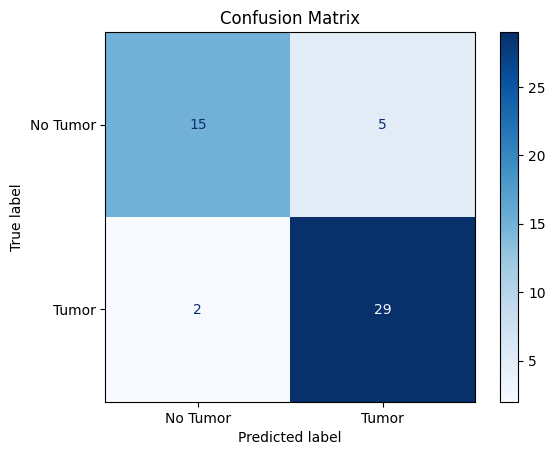

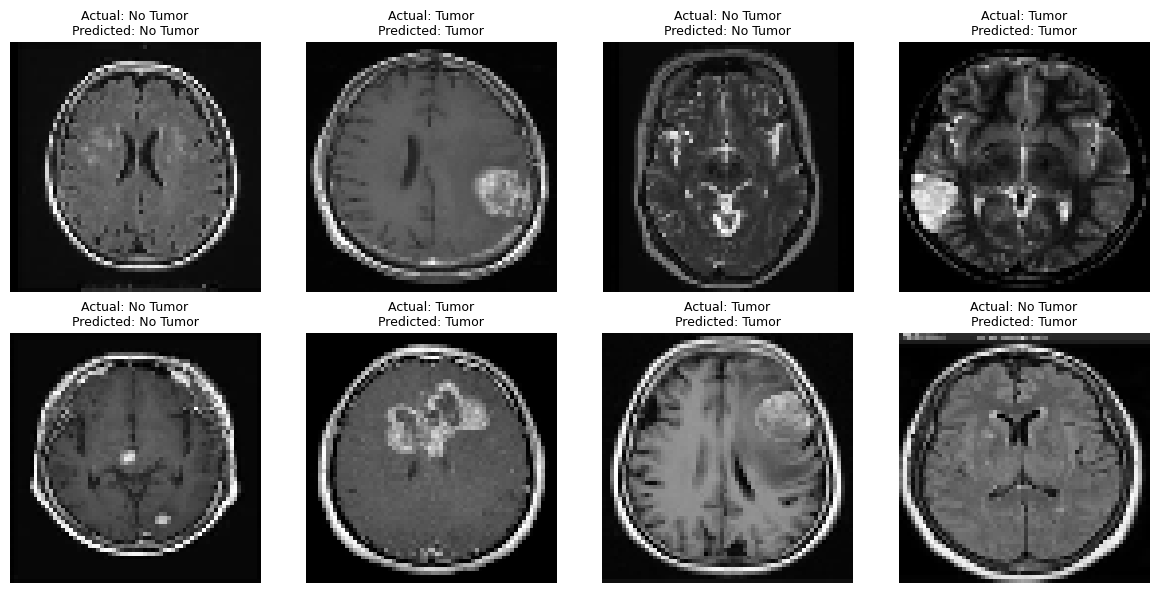

In [2]:
!pip install -q kagglehub opencv-python-headless

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import kagglehub
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

path = kagglehub.dataset_download("navoneel/brain-mri-images-for-brain-tumor-detection")

images = []
labels = []
seen = set()
for root, dirs, files in os.walk(path):
    folder = os.path.basename(root).lower()
    if folder not in ("yes", "no"):
        continue
    for name in sorted(files):
        key = (folder, name)
        if key in seen:
            continue
        img = cv2.imread(os.path.join(root, name), cv2.IMREAD_GRAYSCALE)
        if img is None:
            continue
        seen.add(key)
        images.append(cv2.resize(img, (64, 64)))
        labels.append(1 if folder == "yes" else 0)

images = np.array(images)
labels = np.array(labels)
print("Images loaded:", images.shape, "| Tumor:", labels.sum(), "| No tumor:", (labels == 0).sum())

img_train, img_test, y_train, y_test = train_test_split(
    images, labels, test_size=0.2, stratify=labels, random_state=42
)

X_train = img_train.reshape(len(img_train), -1)
X_test = img_test.reshape(len(img_test), -1)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

svm = SVC(kernel="rbf", C=10, gamma="scale")
svm.fit(X_train, y_train)
y_pred = svm.predict(X_test)

names = ["No Tumor", "Tumor"]
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print()
print(classification_report(y_test, y_pred, target_names=names))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=names).plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(img_test[i], cmap="gray")
    plt.title("Actual: {}\nPredicted: {}".format(names[y_test[i]], names[y_pred[i]]), fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()


## Activity 3: Mall Customers Clustering

(200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


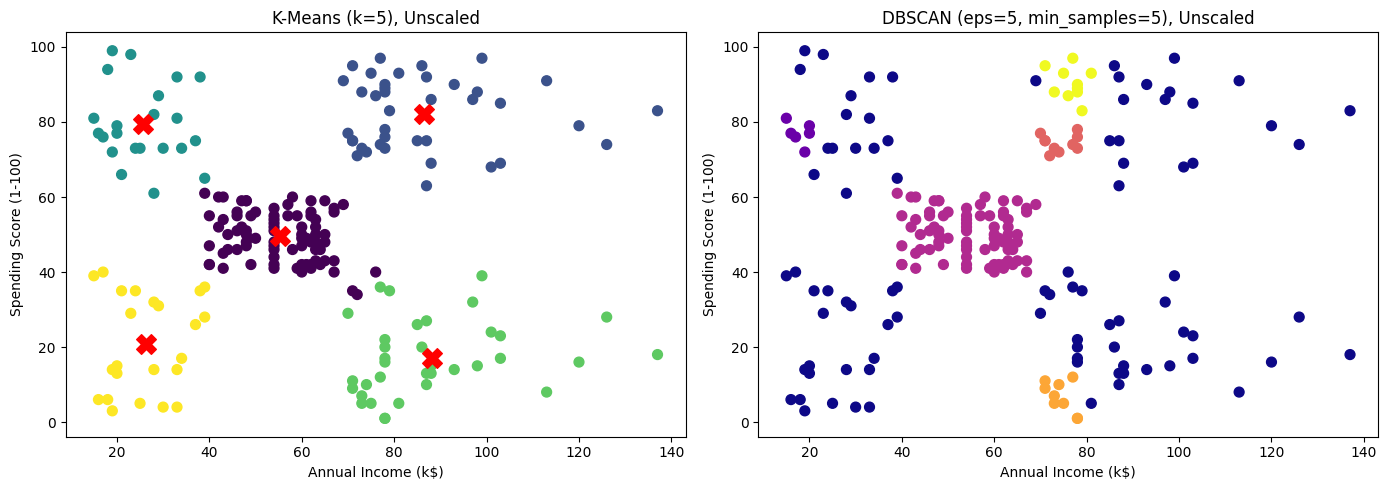

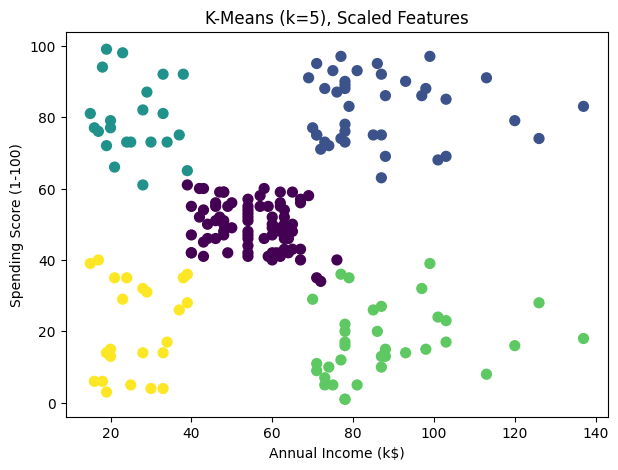

Silhouette (unscaled): 0.5539
Silhouette (scaled): 0.5547
Agreement between unscaled and scaled clusters (ARI): 1.0
Scaling barely changed the clusters because income and spending score are already on similar ranges.


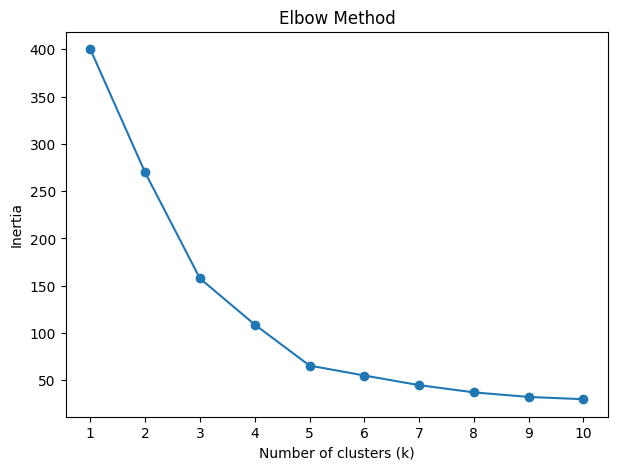

,Customers,Avg_Age,Avg_Income,Avg_Spending
KMeans_Scaled,,,,
0,81,42.7,55.3,49.5
1,39,32.7,86.5,82.1
2,22,25.3,25.7,79.4
3,35,41.1,88.2,17.1
4,23,45.2,26.3,20.9


Cluster interpretation:
Cluster 0: average income, average spending, average age 43, 81 customers
Cluster 1: high income, high spending, average age 33, 39 customers
Cluster 2: low income, high spending, average age 25, 22 customers
Cluster 3: high income, low spending, average age 41, 35 customers
Cluster 4: low income, low spending, average age 45, 23 customers

Silhouette without LuckyNumber: 0.5547
Silhouette with LuckyNumber: 0.3363
Agreement with original clusters (ARI): 0.4912
LuckyNumber has no relation to customer behaviour, but after scaling it counts as much as income and spending score.
It adds random noise to every distance, so clusters become less clean and some customers switch groups.


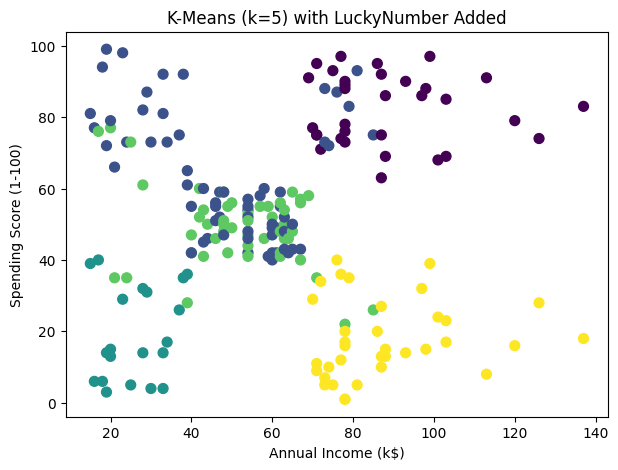

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score

df = pd.read_csv("/content/Mall_Customers.csv")
print(df.shape)
display(df)

income_col = "Annual Income (k$)"
score_col = "Spending Score (1-100)"
X = df[[income_col, score_col]].values

kmeans = KMeans(n_clusters=5, n_init=10, random_state=42)
df["KMeans"] = kmeans.fit_predict(X)

dbscan = DBSCAN(eps=5, min_samples=5)
df["DBSCAN"] = dbscan.fit_predict(X)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(X[:, 0], X[:, 1], c=df["KMeans"], cmap="viridis", s=50)
axes[0].scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], c="red", marker="X", s=200)
axes[0].set_title("K-Means (k=5), Unscaled")
axes[1].scatter(X[:, 0], X[:, 1], c=df["DBSCAN"], cmap="plasma", s=50)
axes[1].set_title("DBSCAN (eps=5, min_samples=5), Unscaled")
for ax in axes:
    ax.set_xlabel("Annual Income (k$)")
    ax.set_ylabel("Spending Score (1-100)")
plt.tight_layout()
plt.show()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
kmeans_scaled = KMeans(n_clusters=5, n_init=10, random_state=42)
df["KMeans_Scaled"] = kmeans_scaled.fit_predict(X_scaled)

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=df["KMeans_Scaled"], cmap="viridis", s=50)
plt.title("K-Means (k=5), Scaled Features")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.show()

ari_scale = adjusted_rand_score(df["KMeans"], df["KMeans_Scaled"])
print("Silhouette (unscaled):", round(silhouette_score(X, df["KMeans"]), 4))
print("Silhouette (scaled):", round(silhouette_score(X_scaled, df["KMeans_Scaled"]), 4))
print("Agreement between unscaled and scaled clusters (ARI):", round(ari_scale, 4))
if ari_scale > 0.9:
    print("Scaling barely changed the clusters because income and spending score are already on similar ranges.")
else:
    print("Scaling changed the clusters noticeably, so some customers moved between groups.")

inertia = []
k_range = range(1, 11)
for k in k_range:
    inertia.append(KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled).inertia_)

plt.figure(figsize=(7, 5))
plt.plot(list(k_range), inertia, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.xticks(list(k_range))
plt.show()

summary = df.groupby("KMeans_Scaled").agg(
    Customers=(income_col, "size"),
    Avg_Age=("Age", "mean"),
    Avg_Income=(income_col, "mean"),
    Avg_Spending=(score_col, "mean")
).round(1)
display(summary)

def level(value, low, high):
    if value < low:
        return "low"
    if value >= high:
        return "high"
    return "average"

print("Cluster interpretation:")
for cluster, row in summary.iterrows():
    income_level = level(row["Avg_Income"], 40, 70)
    spend_level = level(row["Avg_Spending"], 40, 60)
    print("Cluster {}: {} income, {} spending, average age {:.0f}, {} customers".format(
        cluster, income_level, spend_level, row["Avg_Age"], int(row["Customers"])))

np.random.seed(42)
df["LuckyNumber"] = np.random.randint(0, 101, size=len(df))
X_lucky = StandardScaler().fit_transform(df[[income_col, score_col, "LuckyNumber"]])
df["KMeans_Lucky"] = KMeans(n_clusters=5, n_init=10, random_state=42).fit_predict(X_lucky)

ari_lucky = adjusted_rand_score(df["KMeans_Scaled"], df["KMeans_Lucky"])
print()
print("Silhouette without LuckyNumber:", round(silhouette_score(X_scaled, df["KMeans_Scaled"]), 4))
print("Silhouette with LuckyNumber:", round(silhouette_score(X_lucky, df["KMeans_Lucky"]), 4))
print("Agreement with original clusters (ARI):", round(ari_lucky, 4))
print("LuckyNumber has no relation to customer behaviour, but after scaling it counts as much as income and spending score.")
print("It adds random noise to every distance, so clusters become less clean and some customers switch groups.")

plt.figure(figsize=(7, 5))
plt.scatter(df[income_col], df[score_col], c=df["KMeans_Lucky"], cmap="viridis", s=50)
plt.title("K-Means (k=5) with LuckyNumber Added")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.show()
